# 03 · Modelling (M5 + M6)

Model comparison, horizon behaviour, the LSTM benchmark and error analysis, all read from what the pipeline saved.

In [1]:
import sys, json, warnings
sys.path.insert(0, "../src"); warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from utils import path
board = json.loads(path("reports", "scoreboard.json").read_text())
dl = json.loads(path("reports", "dl_result.json").read_text())
tp = pd.read_parquet(path("reports", "test_predictions.parquet"))
print("model version", board["version"])

model version 1.0-5bb519c5


## 1. Cross-validation score vs test score

Models were chosen on CV (training window only). The test column was looked at once, afterwards. If the two orderings agree, selection was sound.

In [2]:
rows = [{"model": c["model"], "cv_rmse": c["cv_rmse"], "cv_std": c["cv_std"], "test_rmse": c["test"]["rmse"],
         "test_mape": c["test"]["mape"], "params": c["params"]} for c in board["volume"]["candidates"]]
pd.DataFrame(rows).sort_values("cv_rmse").round(3)

,model,cv_rmse,cv_std,test_rmse,test_mape,params
3,XGBoost,60.921,3.037,58.286,9.554,"{'learning_rate': 0.05, 'max_depth': 4, 'n_est..."
2,Random Forest,63.437,3.774,58.524,9.387,"{'max_depth': 12, 'n_estimators': 100}"
0,Linear Regression,71.956,0.851,70.396,12.632,{}
1,Decision Tree,73.248,1.929,70.194,11.455,{'max_depth': 8}


In [3]:
print("scratch NumPy linear regression (PRD build-it-once rule):",
      {k: round(v, 3) for k, v in board["volume"]["scratch_linreg"].items()})

scratch NumPy linear regression (PRD build-it-once rule): {'rmse': 73.968, 'mae': 53.229, 'mape': 14.423, 'r2': 0.933, 'final_train_mse': 5563.275, 'epochs': 300}


## 2. How error grows with the forecast horizon

In [4]:
h = pd.DataFrame(board["volume"]["horizons"]).T[["rmse", "mape", "coverage", "avg_half_width"]]
h.index = [f"{int(i) * 30} min" for i in h.index]
h.round(3)

,rmse,mape,coverage,avg_half_width
30 min,58.286,9.554,0.809,65.667
60 min,58.431,9.642,0.803,66.072
90 min,58.448,9.576,0.814,67.422
120 min,58.796,9.820,0.813,68.805


## 3. LSTM vs the classical winner (same test rows)

classical XGBoost    58.29
LSTM                 61.86
BiLSTM               60.45
tuning grid: [{'seq_length': 8, 'hidden_size': 32, 'val_loss': 0.20466074347496033}, {'seq_length': 8, 'hidden_size': 64, 'val_loss': 0.20389710366725922}, {'seq_length': 16, 'hidden_size': 32, 'val_loss': 0.2037043571472168}, {'seq_length': 16, 'hidden_size': 64, 'val_loss': 0.20213328301906586}]


Text(0.5, 1.0, 'Sequence models, validation loss')

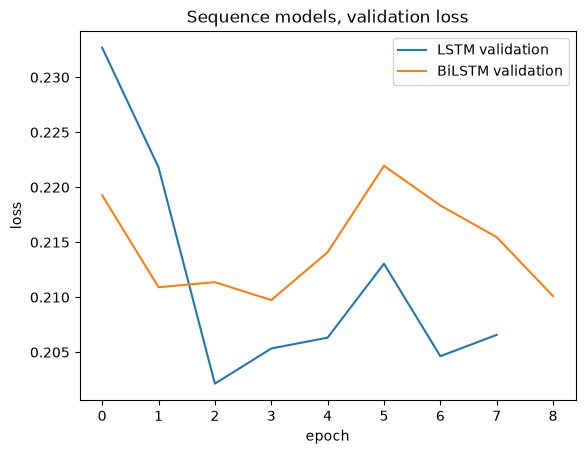

In [5]:
bench = {"classical " + dl["classical"]["model"]: dl["classical"]["rmse"]}
bench.update({k: v["test"]["rmse"] for k, v in dl["variants"].items()})
print(pd.Series(bench).round(2).to_string())
print("tuning grid:", dl["tuning"])
for k, v in dl["variants"].items():
    plt.plot(v["history"]["val"], label=f"{k} validation")
plt.legend(); plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Sequence models, validation loss")

## 4. Error analysis (PRD 13.3)

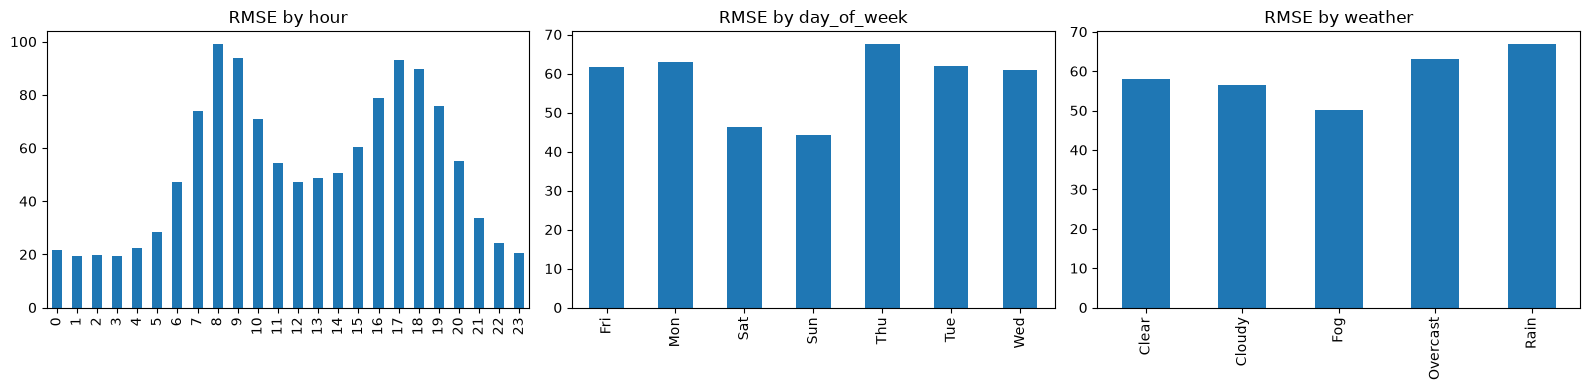

In [6]:
eb = board["volume"]["error_breakdown"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, key in zip(ax, ["hour", "day_of_week", "weather"]):
    pd.Series(eb[key]).plot.bar(ax=a, title=f"RMSE by {key}")
plt.tight_layout()

mean residual -0.15 (bias), skew 0.19


Text(0.5, 1.0, 'Residuals, next-window volume')

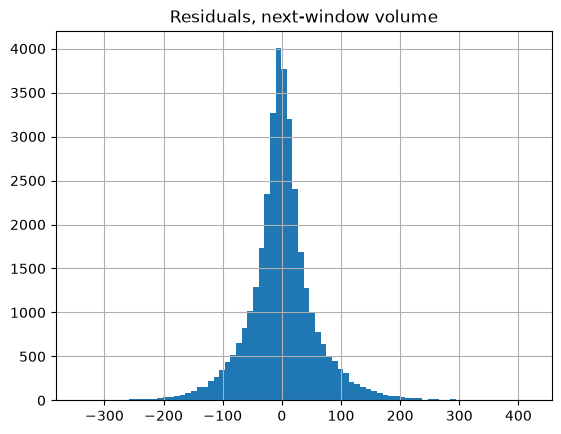

In [7]:
v1 = tp[(tp.target == "traffic_volume") & (tp.horizon == 1)]
resid = v1.actual - v1.pred
print(f"mean residual {resid.mean():.2f} (bias), skew {resid.skew():.2f}")
resid.hist(bins=80); plt.title("Residuals, next-window volume")

## 5. Congestion and accident risk

In [8]:
c = board["congestion"]["test"]
print("macro-F1", round(c["macro_f1"], 3), "| recall by class", c["recall"])
pd.DataFrame(c["confusion_matrix"], index=["Free-flow", "Moderate", "Heavy", "Severe"],
             columns=["Free-flow", "Moderate", "Heavy", "Severe"])

macro-F1 0.769 | recall by class {'Free-flow': 0.954, 'Moderate': 0.838, 'Heavy': 0.66, 'Severe': 0.609}


,Free-flow,Moderate,Heavy,Severe
Free-flow,20326,974,0,0
Moderate,739,7134,625,18
Heavy,0,682,2311,506
Severe,0,6,783,1230


In [9]:
a = board["accident"]["test"]
{k: round(v, 4) if isinstance(v, float) else v for k, v in a.items()}

{'roc_auc': 0.6174,
 'threshold': 0.0128,
 'precision': 0.0267,
 'recall': 0.2122,
 'f1': 0.0474,
 'alerts_per_1000_windows': 77.4891,
 'base_rate': 0.0097,
 'mean_predicted_probability': 0.0087}

Calibration check: the average predicted accident probability should sit close to the real rate. ROC-AUC says how well windows are ranked; calibration says whether the percentages can be read literally.